In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


2025-05-14 20:01:53.380463: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 20:01:53.380487: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [9]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [10]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [11]:
mi_scores.head(10)

dns_0            0.788070
tcp.dstport      0.696608
mqtt3_0          0.652841
mqtt1_0          0.652655
mqtt2_0          0.652334
dns_encoded      0.630067
mqtt1_1          0.629818
dns_1            0.629320
mqtt3_encoded    0.614106
mqtt2_encoded    0.614053
dtype: float64

In [12]:
k = 50
selected_features = mi_scores.head(k).index.tolist()

In [13]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [14]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1361814, 50)
X_val shape: (194545, 50)
X_test shape: (389090, 50)


In [15]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [16]:
best_params = {
  "dense_units": 32,
  "dropout_rate": 0.2,
  "filters": 128,
  "kernel_size": 3,
  "learning_rate": 0.0005
}

best_fit_params = {
    "batch_size": 32,
    "epochs": 50,
}

In [17]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=6,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

2025-05-14 20:24:56.634579: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 20:24:56.637776: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 20:24:56.637931: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-14 20:24:56.638012: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-14 20:24:56.638093: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 48, 128)           512       
                                                                 
 max_pooling1d (MaxPooling1D  (None, 24, 128)          0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 24, 128)           0         
                                                                 
 flatten (Flatten)           (None, 3072)              0         
                                                                 
 dense (Dense)               (None, 32)                98336     
                                                                 
 dense_1 (Dense)             (None, 6)                 198       
                                                        

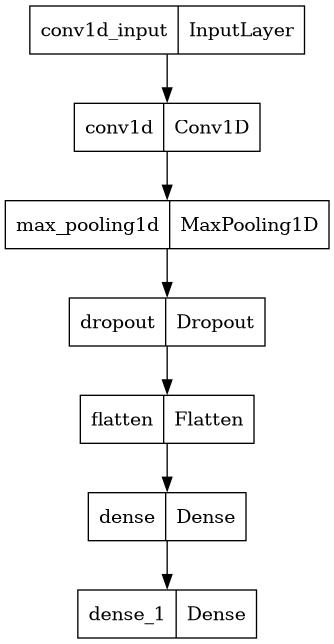

In [18]:
input_shape = (X_train.shape[1], 1)
num_classes = 6
model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes,
                     **best_params)
model.summary()
plot_model(model)

In [19]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("1D-CNN-lr_6" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [20]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=best_fit_params['epochs'],
                    batch_size=best_fit_params['batch_size'],
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=best_fit_params['batch_size'])
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/50
42552/42557 [============================>.] - ETA: 0s - loss: 0.0840 - accuracy: 0.9614
Epoch 00001: val_accuracy improved from -inf to 0.96443, saving model to 1D-CNN-lr_6.h5
42557/42557 [==============================] - 131s 3ms/step - loss: 0.0840 - accuracy: 0.9614 - val_loss: 0.0735 - val_accuracy: 0.9644
Epoch 2/50
42546/42557 [============================>.] - ETA: 0s - loss: 0.0712 - accuracy: 0.9675
Epoch 00002: val_accuracy improved from 0.96443 to 0.97094, saving model to 1D-CNN-lr_6.h5
42557/42557 [==============================] - 133s 3ms/step - loss: 0.0712 - accuracy: 0.9675 - val_loss: 0.0609 - val_accuracy: 0.9709
Epoch 3/50
42543/42557 [============================>.] - ETA: 0s - loss: 0.0663 - accuracy: 0.9704
Epoch 00003: val_accuracy improved from 0.97094 to 0.97326, saving model to 1D-CNN-lr_6.h5
42557/42557 [==============================] - 133s 3ms/step - loss: 0.0663 - accuracy: 0.9704 - val_loss: 0.0579 - val_accuracy: 0.9733
Epoch 4/50
42550/42

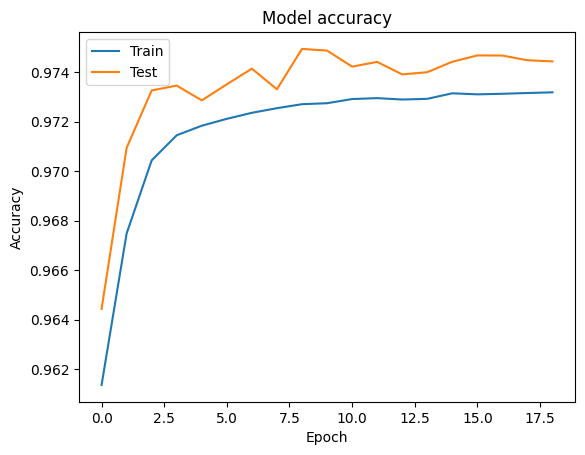

In [21]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

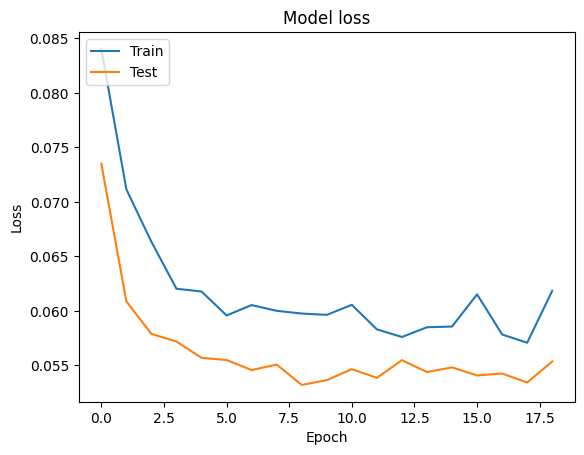

In [22]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [23]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [24]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    280115
        DDoS       0.98      0.97      0.98     57299
    Scanning       0.94      0.94      0.94     14141
   Injection       0.72      0.96      0.82     20702
        MITM       1.00      1.00      1.00        69
     Malware       0.96      0.61      0.75     16764

    accuracy                           0.97    389090
   macro avg       0.93      0.91      0.91    389090
weighted avg       0.98      0.97      0.97    389090



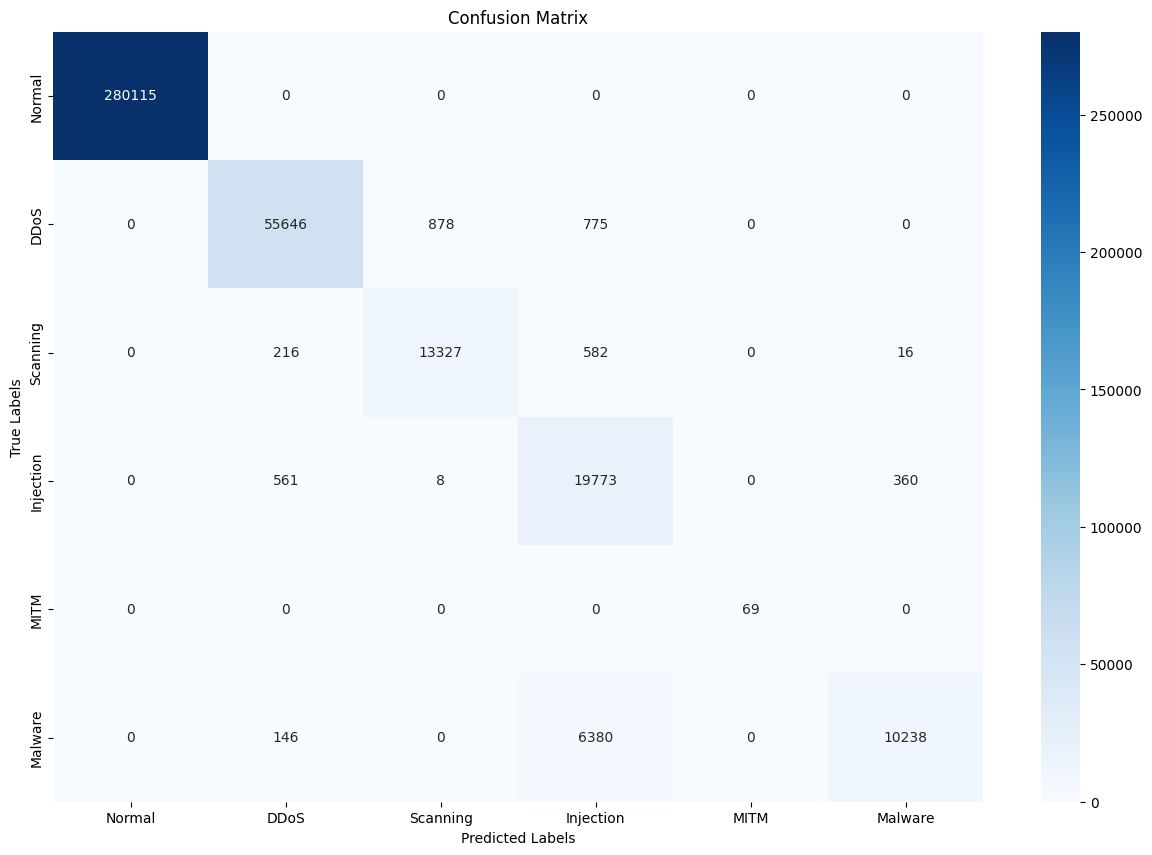

In [25]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

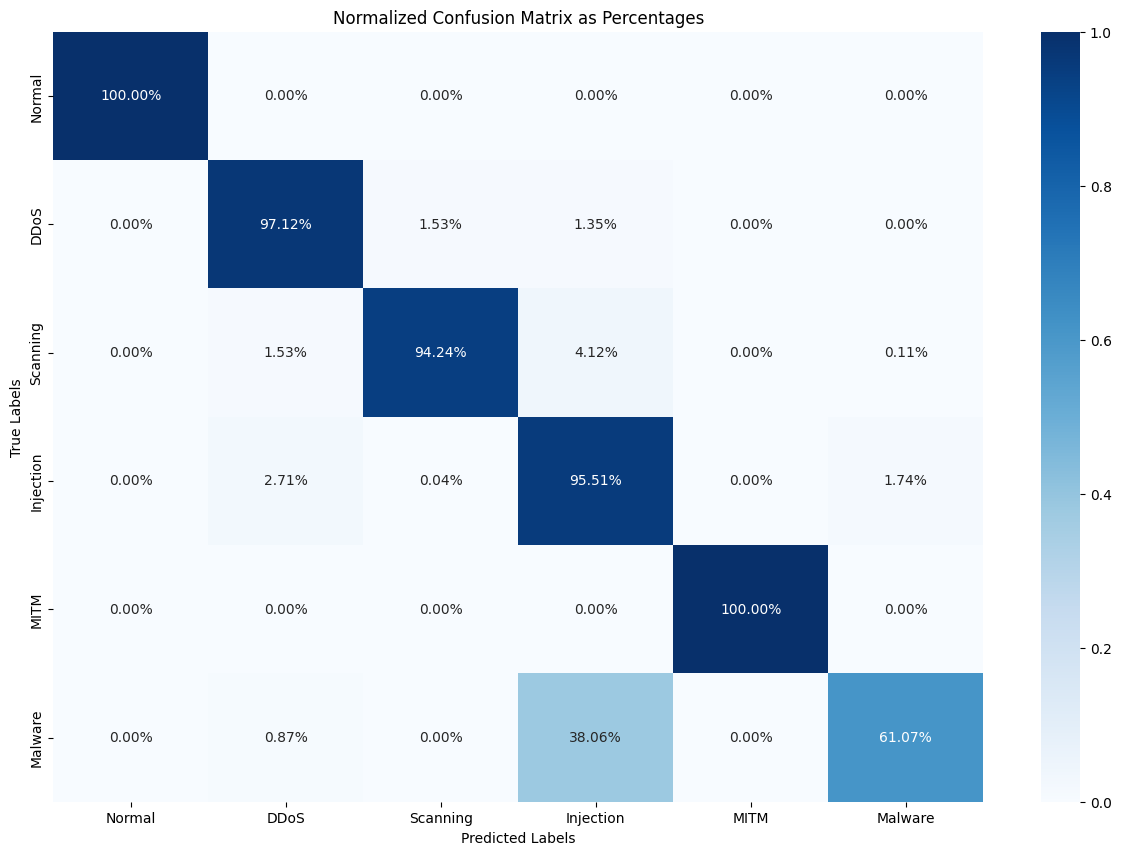

In [26]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')